# Identificando Rostos
Neste curso o objetivo será como identificar rostos em imagens, isso incluí fazer a identificação dos rostos em imagens, bem como marcar eles. A primeira celula de código deste projeto servirá apenas para importar todas as bibliotecas utilizadas, seguidas por uma célula com a função "mostrar", já que não estamos no ambiente do google Colab, a função "imshow" do openCV apenas abre uma janela, se tornando pouco eficiente para este tipo de projeto.

In [1]:
import numpy as np
import cv2
import pytesseract
import matplotlib.pyplot as plt
import os

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/home/juanzito.kkj/Documentos/projetosPessoais/Visão computacional/aula3Rostos/.rostos/lib/python3.12/site-packages/IPython/core/interactiveshell.py", line 3823, in run_code
  File "/tmp/ipykernel_33842/150329863.py", line 3, in <module>
    import pytesseract
  File "/home/juanzito.kkj/Documentos/projetosPessoais/Visão computacional/aula3Rostos/.rostos/lib/python3.12/site-packages/pytesseract/__init__.py", line 2, in <module>
    from .pytesseract import ALTONotSupported
  File "/home/juanzito.kkj/Documentos/projetosPessoais/Visão computacional/aula3Rostos/.rostos/lib/python3.12/site-packages/pytesseract/pytesseract.py", line 29, in <module>
    from PIL import Image
ImportError: cannot import name 'Image' from 'PIL' (unknown location)

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/juanzito.kkj/Documentos/projetosPessoais/Visão computacional/aula3Rostos/.rostos/lib/python

In [ ]:
def mostrar_RGB(img, largura=5, altura=5):
    fig = plt.gcf()
    fig.set_size_inches(largura, altura)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

A partir deste projeto nós conseguimos colocar as imagens que conseguirmos em modelos de machine learning para que o modelo consiga identificar rostos em diferentes ângulos, poses, etc. Além disso aqui nós vamos conseguir identificar expressões faciais, caretas, etc.

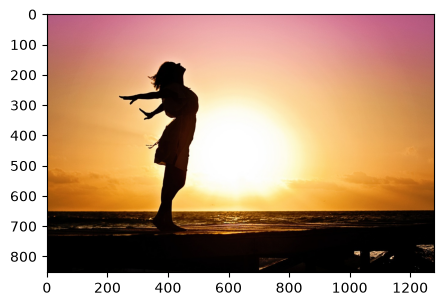

In [ ]:
imagem_original = cv2.imread('imagens/px-girl.jpg')
mostrar_RGB(imagem_original)

Além de mostrar as imagens, é bom que nós consigamos separar os rostos, dessa forma identificando cada rosto separadamente e facilitando a identificação.

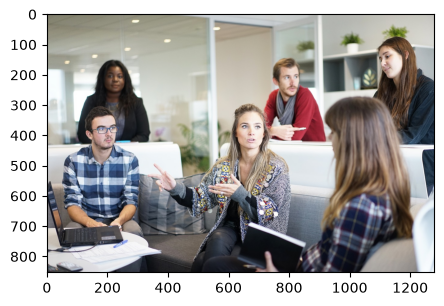

In [ ]:
imagem_original = cv2.imread('imagens/px-people.jpg')
mostrar_RGB(imagem_original)

In [ ]:
imagem_original.shape

(853, 1280, 3)

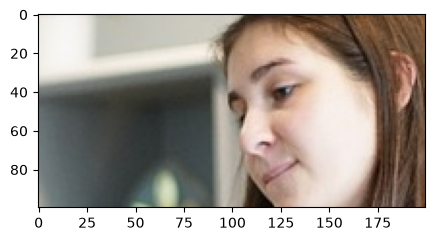

In [ ]:
imagem_roi = imagem_original[100:200, 1000:1200]
mostrar_RGB(imagem_roi)

In [ ]:
cv2.imwrite("imagens/imagem_regionOfInteres.jpg", imagem_roi)

True

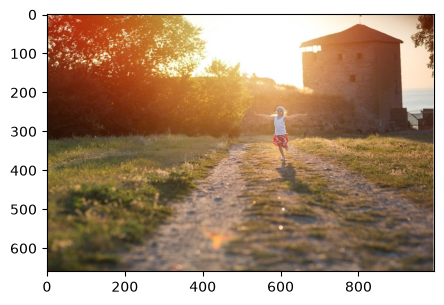

In [ ]:
imagem_original = cv2.imread('imagens/running-kid.png')
mostrar_RGB(imagem_original)

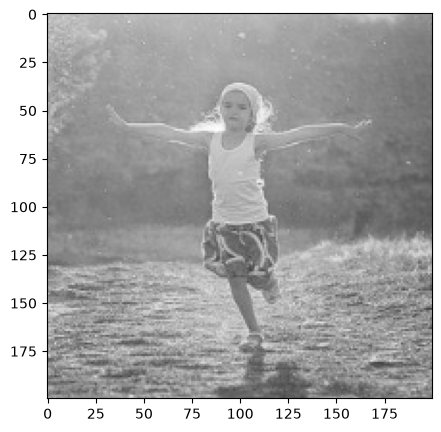

In [ ]:
imagem_roi = imagem_original[200:400, 500:700]
mostrar_RGB(imagem_roi)
imagem_roi = cv2.cvtColor(imagem_roi, cv2.COLOR_BGR2GRAY)
mostrar_RGB(imagem_roi)

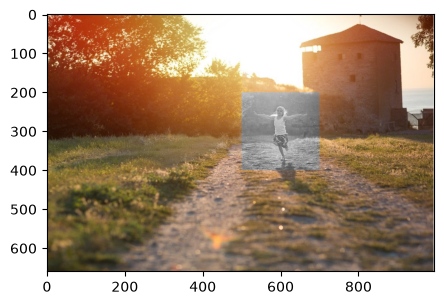

In [ ]:
imagem_original[200:400, 500:700] = cv2.cvtColor(imagem_roi, cv2.COLOR_GRAY2RGB)
mostrar_RGB(imagem_original)

# Classificador de Cascata Haar
uma forma de identificar e classificar diversos rostos

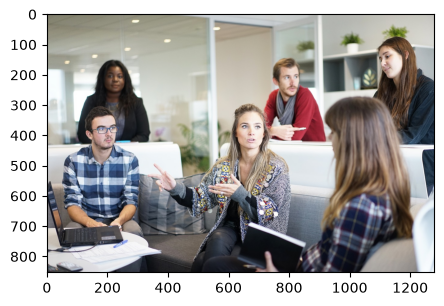

In [ ]:
imagem_original = cv2.imread('imagens/px-people.jpg')
mostrar_RGB(imagem_original)

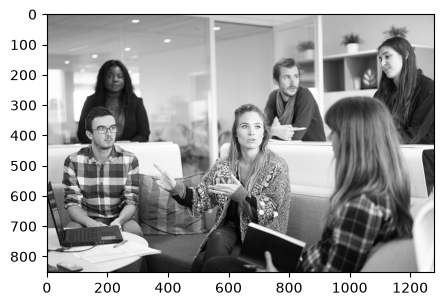

In [ ]:
imagem_gray = cv2.cvtColor(imagem_original, cv2.COLOR_BGR2GRAY)
mostrar_RGB(imagem_gray)

In [ ]:
classificador = cv2.CascadeClassifier('cascades/haarcascade_frontalface_default.xml')

In [ ]:
faces = classificador.detectMultiScale(imagem_gray, 1.1, 5)
len(faces)

5

A seguinte função representa as coordenadas para fazer o retângulo em cada rosto, todos os rostos tem estas caracteristicas.

In [ ]:
faces[0]

array([1088,  105,   95,   95], dtype=int32)

In [ ]:
imagemComRetangulos = imagem_original.copy()

In [ ]:
def destacarFaces(imagem, largura=5, altura=5, cascadeId = 'cascades/haarcascade_frontalface_default.xml', imgScale = 1.1):
    classificador = cv2.CascadeClassifier(cascadeId)
    facesinternas = classificador.detectMultiScale(imagem, imgScale, 5)
    for (x, y, w, h) in facesinternas:
        cv2.rectangle(imagem, (x, y), (x+w, y+h), (255, 0, 0), 5)
    mostrar_RGB(imagem, largura, altura)

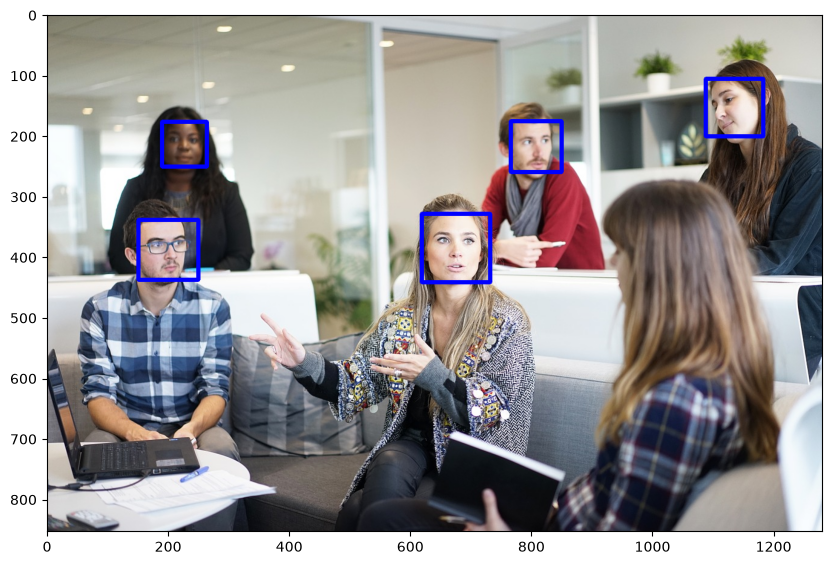

In [ ]:
destacarFaces(imagem_original, 10, 20)

In [ ]:
def salvarImagem(imagem, nomeDaImagem):
    cv2.imwrite(f"imagens/praticasDaAula/{nomeDaImagem}.png", imagem)

In [ ]:
def recortarRostos(imagem, nomeDaImagem, cascadeId = 'cascades/haarcascade_frontalface_default.xml'):
    classificador = cv2.CascadeClassifier(cascadeId)
    facesInternas = classificador.detectMultiScale(imagem, 1.1)
    for (x, y, w, h) in facesInternas:
        salvarImagem(imagem[y:y+h, x:x+w], f"{nomeDaImagem}")
    return mostrar_RGB(imagem[y:y+h, x:x+w])

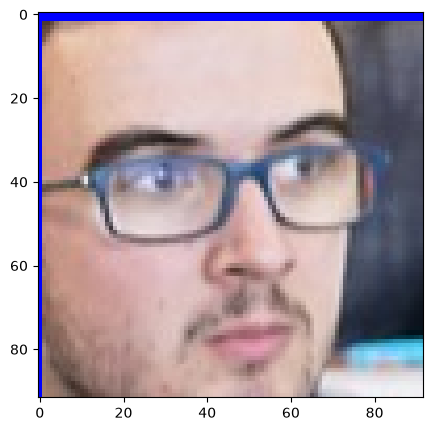

In [ ]:
recortarRostos(imagem_original, 'ensaio1_recortado')

# Botando a aula em prática
temos novas imagens para analisarmos os rostos delas

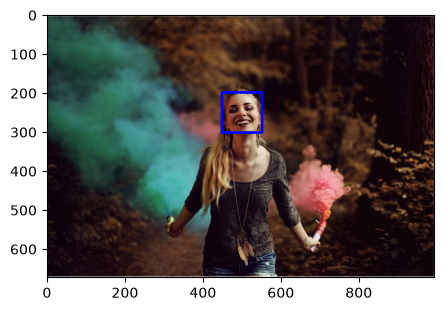

In [ ]:
imagem_original = cv2.imread('imagens/praticasDaAula/ensaio1.png')
destacarFaces(imagem_original, cascadeId='cascades/haarcascade_frontalface_alt.xml', imgScale= 1.1)

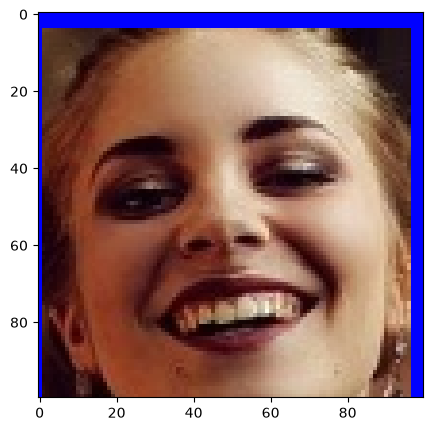

In [ ]:
recortarRostos(imagem_original, 'ensaio1_recortado')

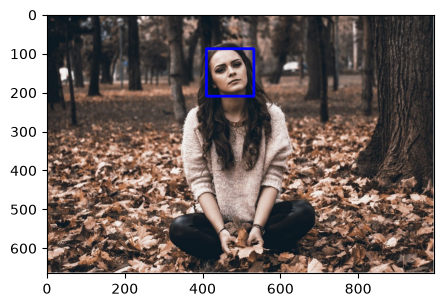

In [ ]:
imagem_original = cv2.imread('imagens/praticasDaAula/ensaio2.png')
destacarFaces(imagem_original)

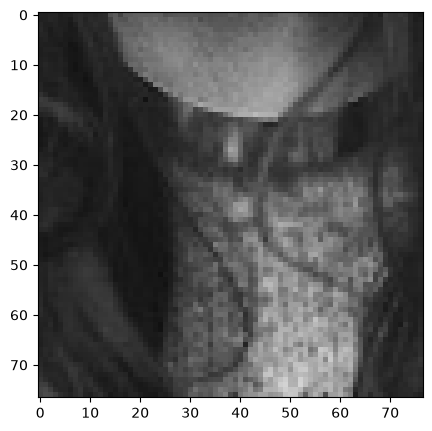

In [ ]:
recortarRostos(cv2.cvtColor(imagem_original, cv2.COLOR_BGR2GRAY), 'ensaio2_recortado')

# Classificação de faces
Agora, depois de aprendermos à identificar e separar as faces, vamos aprender a identificar a pessoa a quem a face pertence.